# Search for the best chain

I am testing every combination of the steps below on the 6 synthetic examples and looking for the chain with the highest F1. Then I check it with leave-one-out (choosing on 5 examples, testing on the 6th), because choosing on all 6 gives too optimistic score.

Steps in the chain (in this order):
1. **frequency filter** on the raw signal (FFT along time in each channel): none, low-pass, high-pass, band-pass
2. **feature**: abs or grad (how fast pixel is changing)
3. **channel normalization**: none, - median of column, / median of column
4. **gamma**: only together with blur, without blur it does not change the mask (percentile keeps the same pixels)
5. **blur** along time: none, 0.1 s, 0.5 s
6. **threshold**: pixel above percentile
7. **opening** along time: none, 5, 25, 125 samples

In [1]:
import numpy as np

import matplotlib.pyplot as plt
from datetime import datetime
import pandas as pd
import datetime
import glob
import json
import cv2
from matplotlib.colors import Normalize
import os
import time
from functools import partial
from concurrent.futures import ThreadPoolExecutor

In [2]:
def set_axis(x, no_labels = 7)->tuple[np.array, np.array]:
    """Sets the x-axis positions and labels for a plot.

    Args:
        x (np.array): The x-axis data.
        no_labels (int, optional): The number of labels to display. Defaults to 7.

    Returns:
        tuple[np.array, np.array]: A tuple containing:
            - The positions of the labels on the x-axis.
            - The labels themselves.
    """
    nx = x.shape[0]
    step_x = int(nx / (no_labels - 1)) 
    x_positions = np.arange(0,nx,step_x) 
    x_labels = x[::step_x]
    return x_positions, x_labels



DX = 5.106500953873407
DT = 0.0016


def read_das_file(files):
    data = np.concatenate([np.load(f) for f in files])
    time_start = datetime.datetime.strptime('2024-05-07 ' + files[0][-10:-4], "%Y-%m-%d %H%M%S")
    index = pd.date_range(start=time_start, periods=len(data), freq=f'{DT}s')
    columns = np.arange(len(data[0])) * DX
    return pd.DataFrame(data=data, index=index, columns=columns)

files = sorted(glob.glob('20240507/*.npy'))
df_real = read_das_file([f for f in files if '091052' <= f[-10:-4] <= '091242'])

files2 = sorted(glob.glob('20240507/*.npy'))
df_real2 = read_das_file([f for f in files2 if '091152' <= f[-10:-4] <= '091342'])

In [3]:
synthetic = {}
for i in range(40, 46):
    signal = np.load(f'Synthetic Dataset/{i}_signal.npy')
    index = np.arange(len(signal)) * DT
    columns = np.arange(signal.shape[1]) * DX
    synthetic[i] = {
        'signal': pd.DataFrame(signal, index=index, columns=columns),
        'ground_truth': pd.DataFrame(np.load(f'Synthetic Dataset/{i}_ground_truth.npy'), index=index, columns=columns),
        'vehicles': pd.DataFrame(json.load(open(f'Synthetic Dataset/{i}_metadata.json'))['ground_truth']['vehicles']).set_index('marker_value'),
    }

In [4]:
def evaluate(pred, gt):
    pred, gt = pred > 0, gt > 0
    tp = (pred & gt).sum()
    if tp == 0:
        return 0.0, 0.0, 0.0
    precision = tp / pred.sum()
    recall = tp / gt.sum()
    return precision, recall, 2 * precision * recall / (precision + recall)

## Steps

In [5]:
def fft_filter(x, low=None, high=None):
    """Keeps only frequencies between low and high [Hz] in each channel (FFT along time, on the signed signal)."""
    spectrum = np.fft.rfft(x, axis=0)
    freqs = np.fft.rfftfreq(len(x), DT)
    if low:
        spectrum[freqs < low] = 0
    if high:
        spectrum[freqs > high] = 0
    return np.fft.irfft(spectrum, n=len(x), axis=0).astype(np.float32)


def minus_column_median(x):
    return x - np.median(x, axis=0)


def divide_by_column_median(x):
    return x / np.median(x, axis=0)


def gamma_blur(x, gamma, size):
    """Gamma correction (on values >= 0), then moving average along time with a window of `size` samples."""
    if gamma != 1:
        x = np.clip(x, 0, None) ** gamma
    if size:
        x = cv2.blur(x, (1, size))
    return x


FILTERS = {'none': lambda x: x}
FILTERS |= {f'low-pass {h} Hz': partial(fft_filter, high=h) for h in [10, 30, 100]}
FILTERS |= {f'high-pass {l} Hz': partial(fft_filter, low=l) for l in [1, 5, 20]}
FILTERS |= {f'band-pass {l}-{h} Hz': partial(fft_filter, low=l, high=h) for l, h in [(1, 30), (1, 100), (5, 30), (5, 100)]}

FEATURES = {'abs': np.abs, 'grad': lambda x: np.abs(np.gradient(x, axis=0))}

NORMALIZATIONS = {'none': lambda x: x, '- median': minus_column_median, '/ median': divide_by_column_median}

BLURS = {'none': 0, '0.1 s': int(0.1 / DT), '0.5 s': int(0.5 / DT)}   # window in samples
GAMMAS = [1, 0.5, 2]
# gamma changes the mask only when blur comes after it, so without blur only gamma 1 is tested
GAMMA_BLUR = [(1, 'none')] + [(g, b) for b in BLURS if b != 'none' for g in GAMMAS]

PERCENTILES = np.r_[30:90:5, 88, 90:100]
OPENINGS = [0, 5, 25, 125]   # opening kernel length along time in samples (0 = no opening)

CHAIN = ['filter', 'feature', 'normalization', 'gamma', 'blur', 'percentile', 'opening']
print(len(FILTERS) * len(FEATURES) * len(NORMALIZATIONS) * len(GAMMA_BLUR) * len(PERCENTILES) * len(OPENINGS), 'chains')


def run_chain(signal, filter_name, feature, normalization, gamma, blur, percentile, opening):
    """Runs one chain on a signal (time x channels) and returns the mask of detected vehicles."""
    score = gamma_blur(NORMALIZATIONS[normalization](FEATURES[feature](FILTERS[filter_name](signal))), gamma, BLURS[blur])
    mask = (score > np.percentile(score, percentile)).astype(np.uint8)
    if opening:
        mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, np.ones((opening, 1), np.uint8))
    return mask > 0


def chain_label(chain):
    """Short name of a chain, skipping steps that are not used."""
    filter_name, feature, normalization, gamma, blur, percentile, opening = chain
    parts = [filter_name if filter_name != 'none' else None,
             feature,
             normalization if normalization != 'none' else None,
             f'gamma {gamma:g}' if gamma != 1 else None,
             f'blur {blur}' if blur != 'none' else None,
             f'> {percentile}th',
             f'opening {opening}x1' if opening else None]
    return ' > '.join(part for part in parts if part)

42504 chains


## Search

Every chain on every synthetic example. Results are saved to `search_results.csv`, so the search runs only once.

In [6]:
def search_sample(i):
    """F1 of every chain on synthetic example i. Each step is computed once and reused by all chains that share it."""
    signal = synthetic[i]['signal'].values
    gt = synthetic[i]['ground_truth'].values > 0
    gt_count = np.count_nonzero(gt)
    rows = []
    for filter_name, filter_fn in FILTERS.items():
        filtered = filter_fn(signal)
        for feature_name, feature_fn in FEATURES.items():
            feature = feature_fn(filtered)
            for norm_name, norm_fn in NORMALIZATIONS.items():
                normalized = norm_fn(feature)
                for gamma, blur in GAMMA_BLUR:
                    score = gamma_blur(normalized, gamma, BLURS[blur])
                    for percentile, threshold in zip(PERCENTILES, np.percentile(score, PERCENTILES)):
                        mask = (score > threshold).astype(np.uint8)
                        for opening in OPENINGS:
                            pred = cv2.morphologyEx(mask, cv2.MORPH_OPEN, np.ones((opening, 1), np.uint8)) if opening else mask
                            tp = np.count_nonzero(pred[gt])
                            f1 = 2 * tp / (np.count_nonzero(pred) + gt_count)   # same as 2PR / (P + R)
                            rows.append((filter_name, feature_name, norm_name, gamma, blur, percentile, opening, i, f1))
    return rows


RESULTS_FILE = 'search_results.csv'   # delete this file after changing the steps, so the search runs again

if os.path.exists(RESULTS_FILE):
    results = pd.read_csv(RESULTS_FILE, keep_default_na=False)
else:
    start = time.time()
    with ThreadPoolExecutor(len(synthetic)) as pool:
        rows = [row for sample_rows in pool.map(search_sample, synthetic) for row in sample_rows]
    results = pd.DataFrame(rows, columns=CHAIN + ['sample', 'f1'])
    results.to_csv(RESULTS_FILE, index=False)
    print(f'search took {time.time() - start:.0f} s')

f1 = results.pivot_table(index=CHAIN, columns='sample', values='f1')
f1['mean F1'] = f1.mean(axis=1)
f1 = f1.sort_values('mean F1', ascending=False)
f1.head(15).round(3)

search took 690 s


sample                                                                      40  \
filter             feature normalization gamma blur  percentile opening          
band-pass 1-100 Hz grad    / median      1.0   0.1 s 88         0        0.364   
low-pass 100 Hz    grad    / median      1.0   0.1 s 88         0        0.364   
band-pass 1-100 Hz grad    / median      1.0   0.1 s 88         5        0.364   
low-pass 100 Hz    grad    / median      1.0   0.1 s 88         5        0.363   
band-pass 1-100 Hz grad    / median      2.0   0.1 s 88         0        0.363   
low-pass 100 Hz    grad    / median      2.0   0.1 s 88         0        0.364   
band-pass 1-100 Hz grad    / median      1.0   0.1 s 88         25       0.363   
low-pass 100 Hz    grad    / median      1.0   0.1 s 88         25       0.363   
                                         2.0   0.1 s 88         5        0.363   
band-pass 1-100 Hz grad    / median      2.0   0.1 s 88         5        0.363   
                                                                25       0.363   
low-pass 100 Hz    grad    / median      2.0   0.1 s 88         25       0.363   
band-pass 1-100 Hz grad    - median      1.0   0.1 s 88         25       0.353   
low-pass 100 Hz    grad    - median      1.0   0.1 s 88         25       0.353   
                           / median      0.5   0.1 s 88         0        0.363   

sample                                                                      41  \
filter             feature normalization gamma blur  percentile opening          
band-pass 1-100 Hz grad    / median      1.0   0.1 s 88         0        0.357   
low-pass 100 Hz    grad    / median      1.0   0.1 s 88         0        0.357   
band-pass 1-100 Hz grad    / median      1.0   0.1 s 88         5        0.357   
low-pass 100 Hz    grad    / median      1.0   0.1 s 88         5        0.357   
band-pass 1-100 Hz grad    / median      2.0   0.1 s 88         0        0.357   
low-pass 100 Hz    grad    / median      2.0   0.1 s 88         0        0.357   
band-pass 1-100 Hz grad    / median      1.0   0.1 s 88         25       0.358   
low-pass 100 Hz    grad    / median      1.0   0.1 s 88         25       0.359   
                                         2.0   0.1 s 88         5        0.357   
band-pass 1-100 Hz grad    / median      2.0   0.1 s 88         5        0.357   
                                                                25       0.358   
low-pass 100 Hz    grad    / median      2.0   0.1 s 88         25       0.358   
band-pass 1-100 Hz grad    - median      1.0   0.1 s 88         25       0.362   
low-pass 100 Hz    grad    - median      1.0   0.1 s 88         25       0.362   
                           / median      0.5   0.1 s 88         0        0.356   

sample                                                                      42  \
filter             feature normalization gamma blur  percentile opening          
band-pass 1-100 Hz grad    / median      1.0   0.1 s 88         0        0.361   
low-pass 100 Hz    grad    / median      1.0   0.1 s 88         0        0.361   
band-pass 1-100 Hz grad    / median      1.0   0.1 s 88         5        0.361   
low-pass 100 Hz    grad    / median      1.0   0.1 s 88         5        0.361   
band-pass 1-100 Hz grad    / median      2.0   0.1 s 88         0        0.362   
low-pass 100 Hz    grad    / median      2.0   0.1 s 88         0        0.362   
band-pass 1-100 Hz grad    / median      1.0   0.1 s 88         25       0.362   
low-pass 100 Hz    grad    / median      1.0   0.1 s 88         25       0.362   
                                         2.0   0.1 s 88         5        0.362   
band-pass 1-100 Hz grad    / median      2.0   0.1 s 88         5        0.361   
                                                                25       0.362   
low-pass 100 Hz    grad    / median      2.0   0.1 s 88         25       0.362   
band-pass 1-100 Hz grad    - median      1.0   0.1 s 88       

## Leave-one-out

I choose the best chain on 5 examples and check its F1 on the 6th one.

In [7]:
samples = list(synthetic)
loo = []
for k in samples:
    others = [s for s in samples if s != k]
    chosen = f1[others].mean(axis=1).idxmax()
    loo.append({'held out': k,
                'chain chosen on the other 5': chain_label(chosen),
                'F1 on the other 5': f1.loc[chosen, others].mean(),
                'F1 on held out': f1.loc[chosen, k]})
loo = pd.DataFrame(loo).set_index('held out')
display(loo.round(3))
print(f"leave-one-out F1: {loo['F1 on held out'].mean():.3f}   (best chain tuned on all 6: {f1['mean F1'].iloc[0]:.3f})")

,chain chosen on the other 5,F1 on the other 5,F1 on held out
held out,,,
40,band-pass 1-100 Hz > grad > - median > blur 0....,0.361,0.353
41,band-pass 1-100 Hz > grad > / median > gamma 2...,0.362,0.336
42,band-pass 1-100 Hz > grad > - median > blur 0....,0.361,0.354
43,band-pass 1-100 Hz > grad > / median > blur 0....,0.355,0.385
44,band-pass 1-100 Hz > grad > / median > blur 0....,0.360,0.363
45,low-pass 100 Hz > grad > - median > blur 0.1 s...,0.367,0.323


leave-one-out F1: 0.352   (best chain tuned on all 6: 0.360)


## Which steps matter

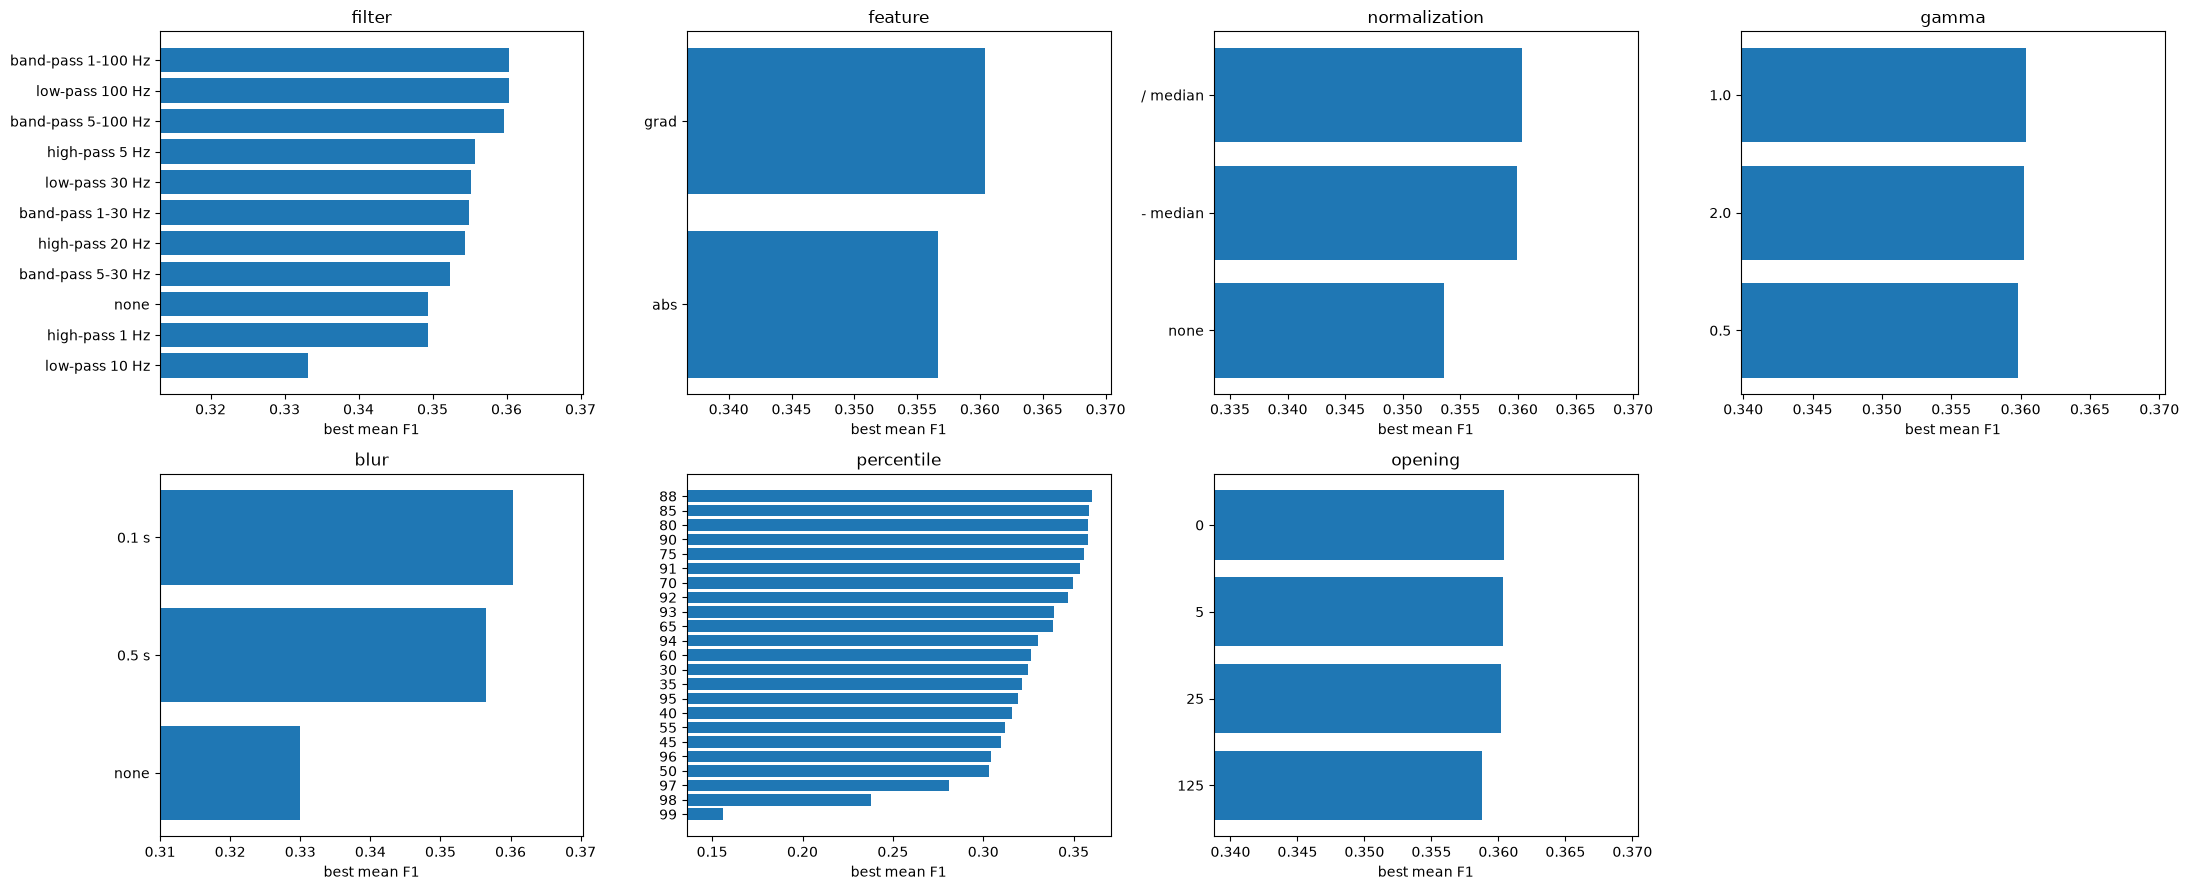

In [8]:
# for every option of every step: the best mean F1 it can reach (with the best choice of all other steps)
fig, axes = plt.subplots(2, 4, figsize=(22, 9))
for ax, step in zip(axes.ravel(), CHAIN):
    best = f1.groupby(level=step)['mean F1'].max().sort_values()
    ax.barh(best.index.astype(str), best.values)
    ax.set_xlim(best.min() - 0.02, best.max() + 0.01)
    ax.set_title(step)
    ax.set_xlabel('best mean F1')
axes.ravel()[-1].axis('off')
plt.tight_layout()
plt.show()

## Best chain

In [9]:
best = f1.index[0]
print('best chain:', chain_label(best))
scores = pd.DataFrame({i: evaluate(run_chain(s['signal'].values, *best), s['ground_truth'].values)
                       for i, s in synthetic.items()}, index=['precision', 'recall', 'f1']).T
scores.loc['mean'] = scores.mean()
scores.round(3)

best chain: band-pass 1-100 Hz > grad > / median > blur 0.1 s > > 88th


,precision,recall,f1
40,0.270,0.559,0.364
41,0.237,0.723,0.357
42,0.248,0.666,0.361
43,0.291,0.574,0.386
44,0.281,0.514,0.363
45,0.226,0.618,0.331
mean,0.259,0.609,0.360


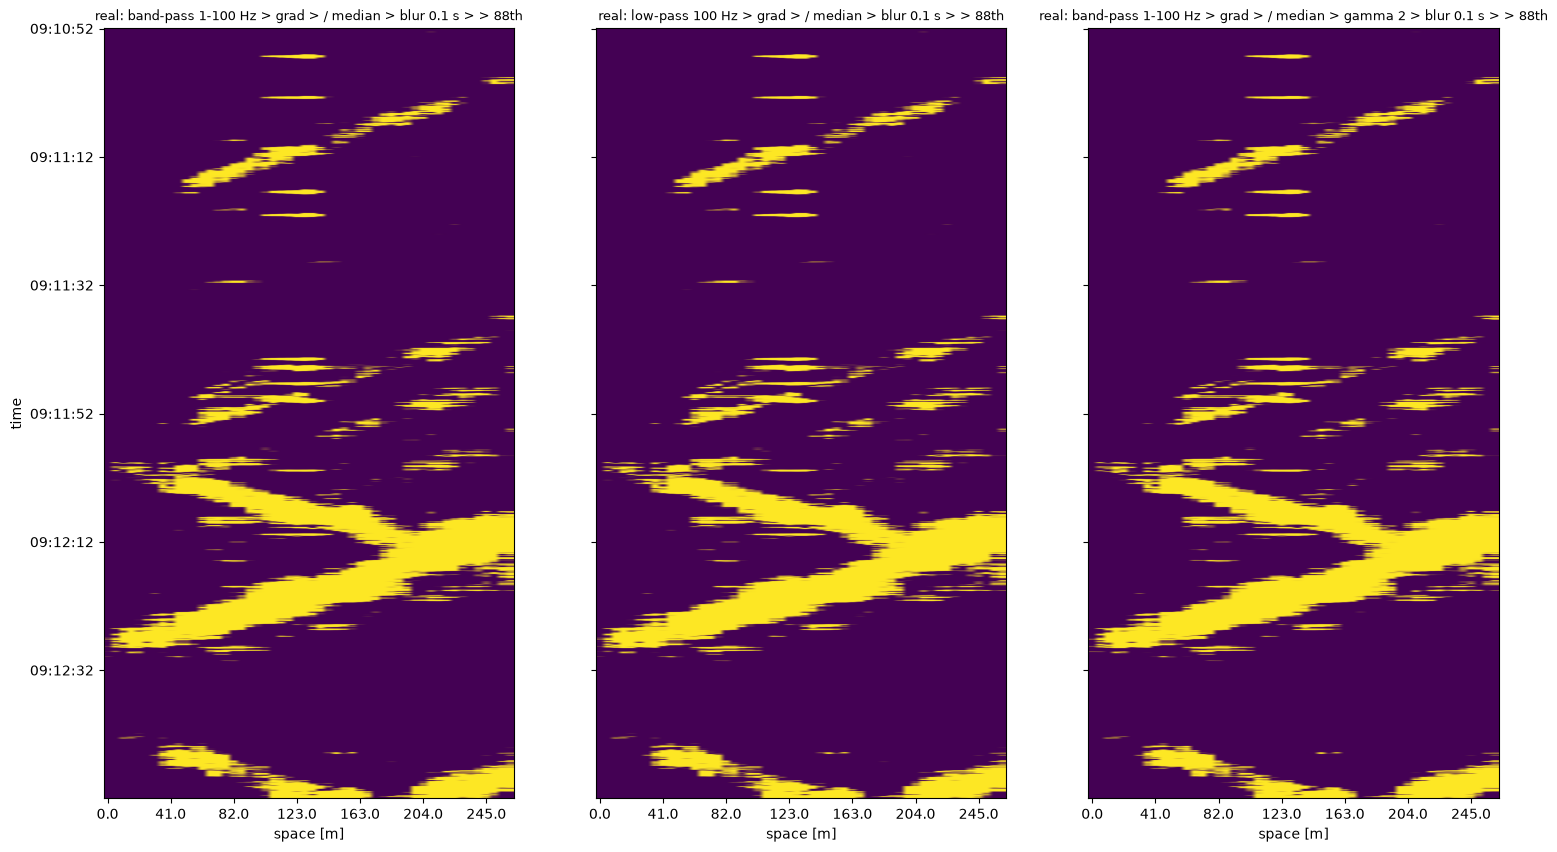

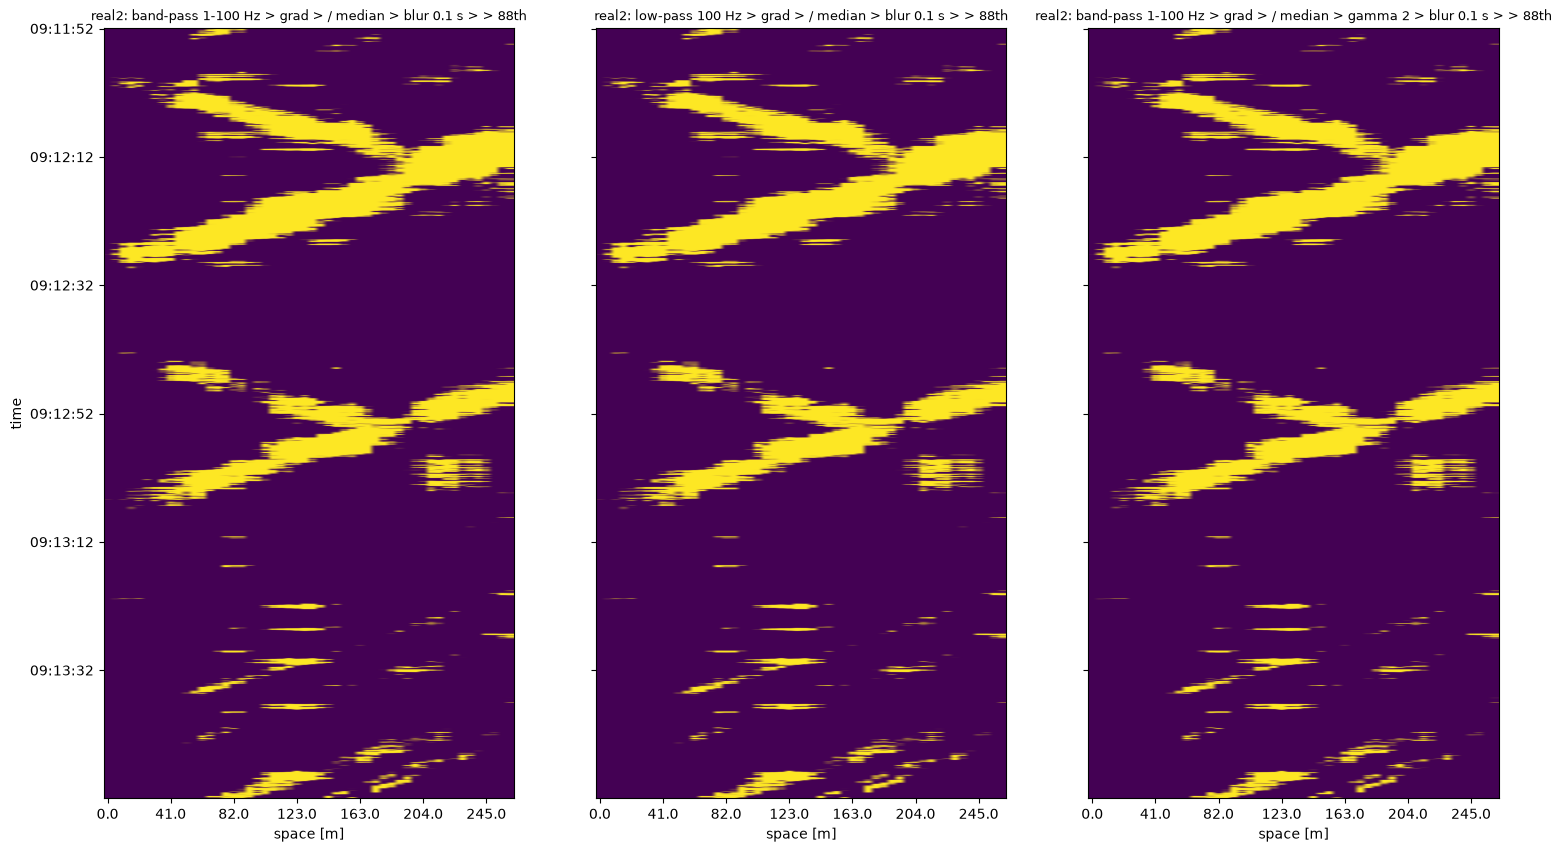

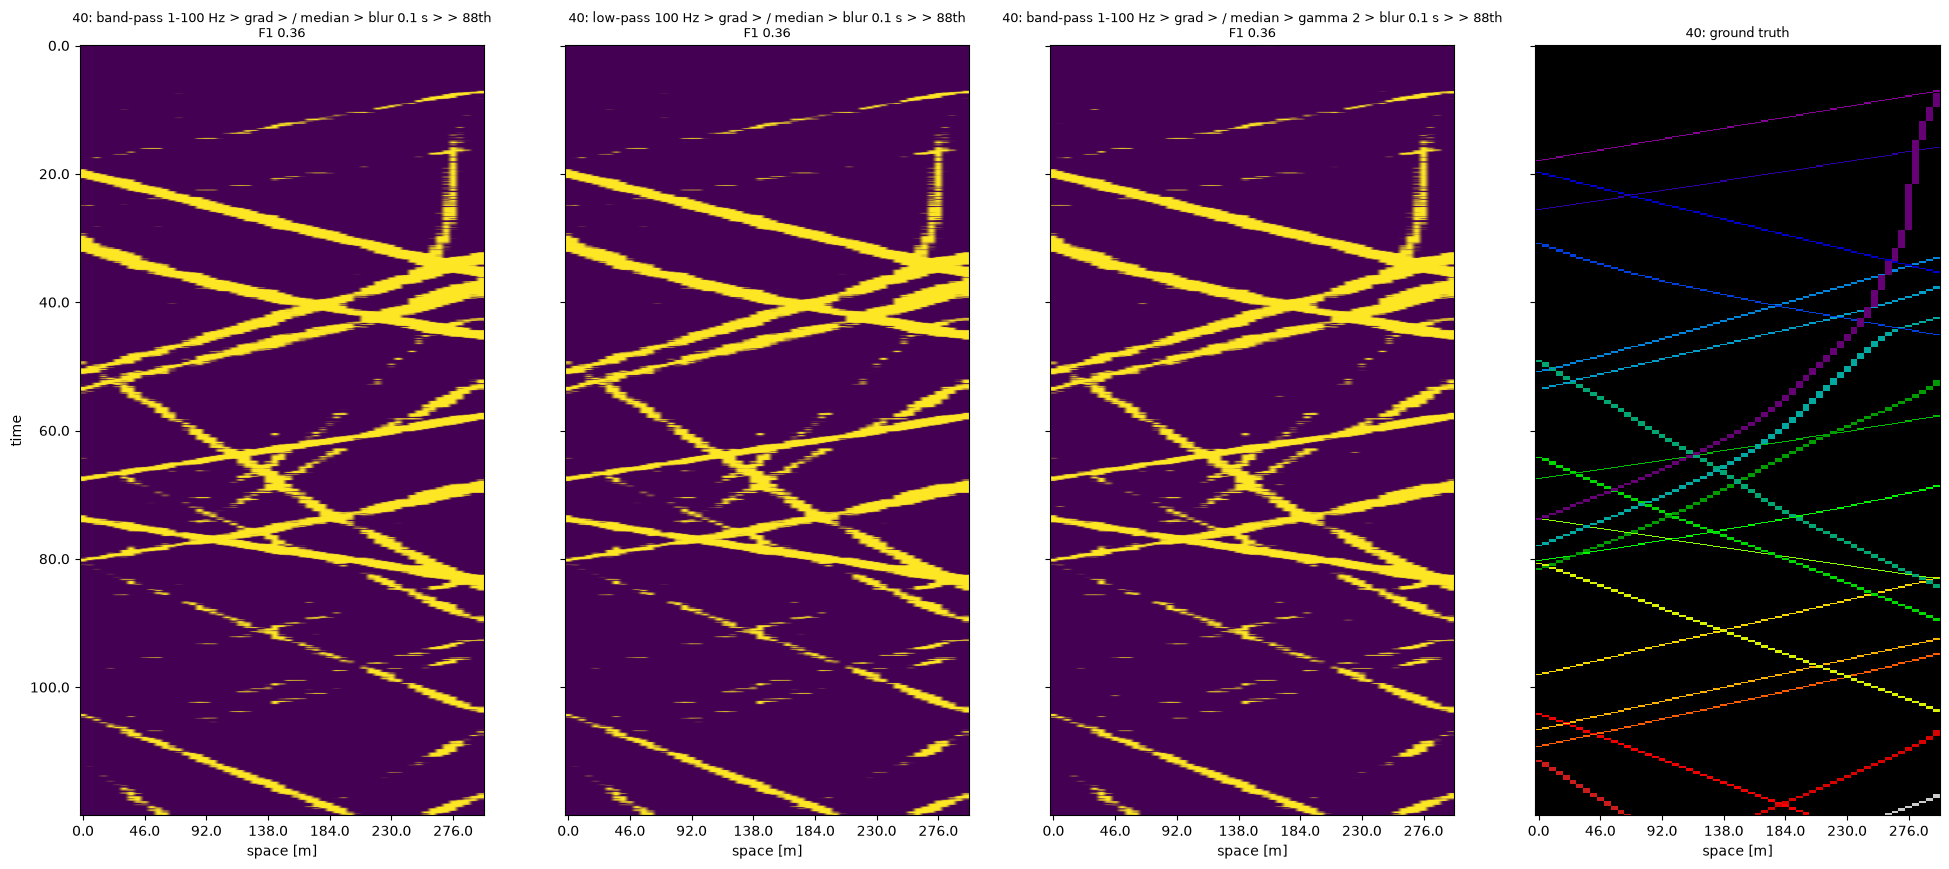

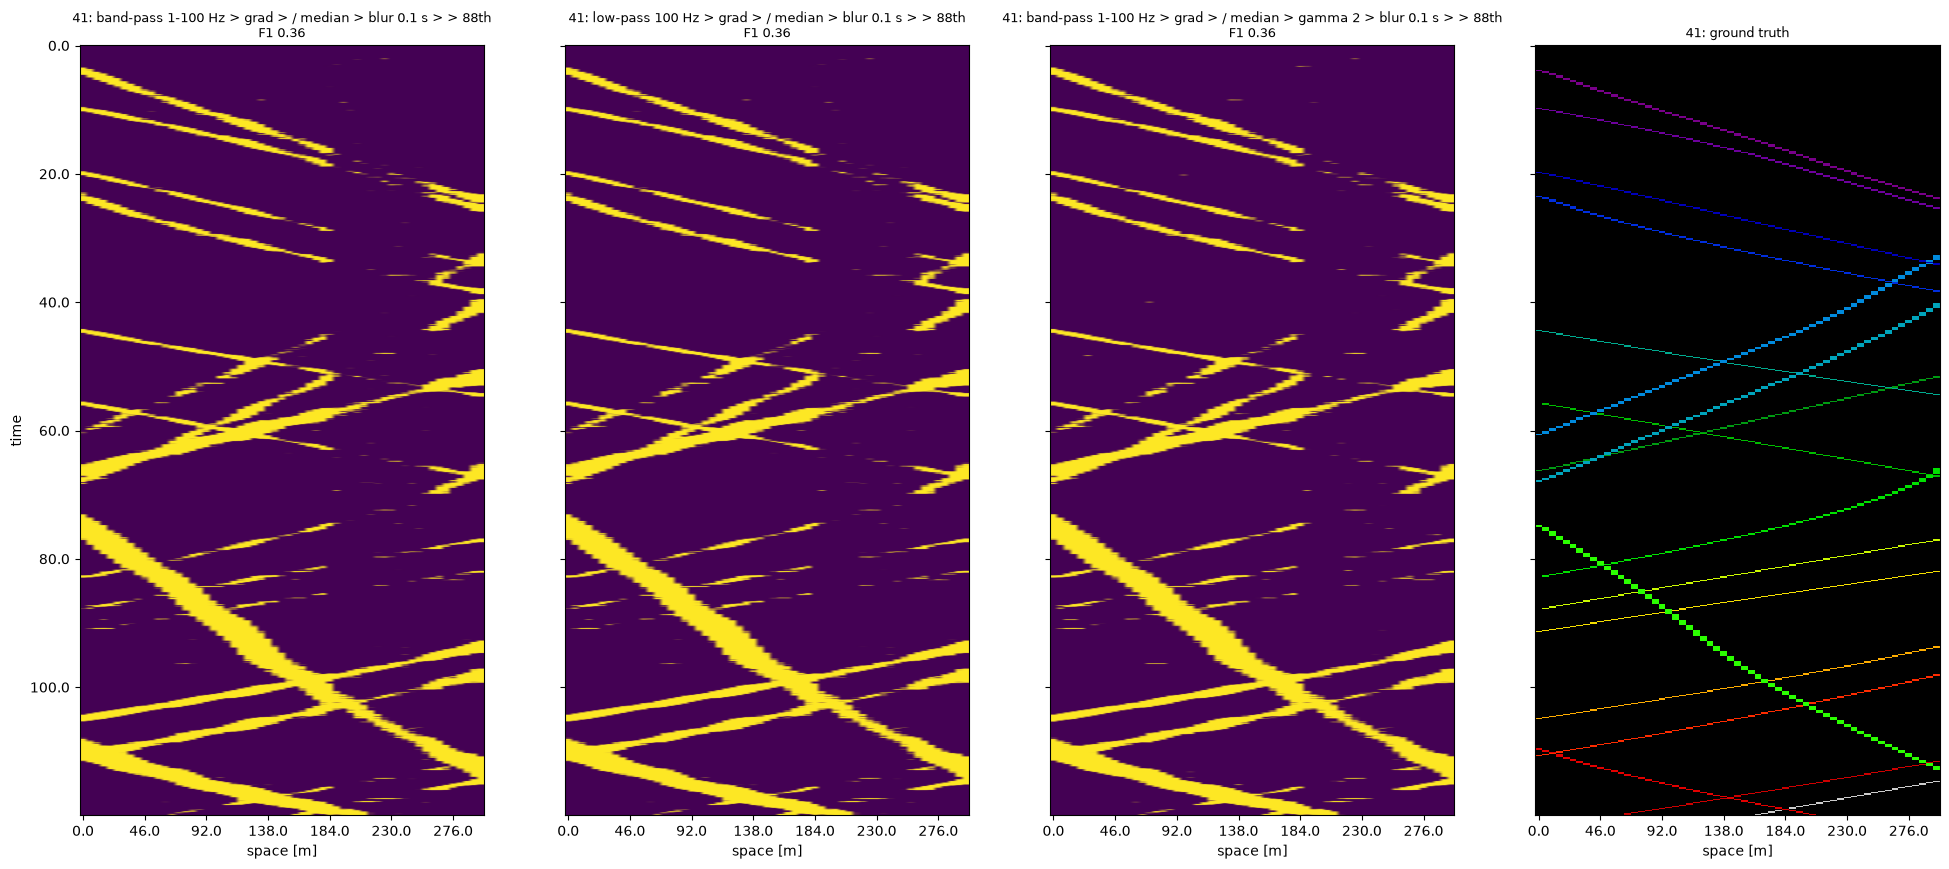

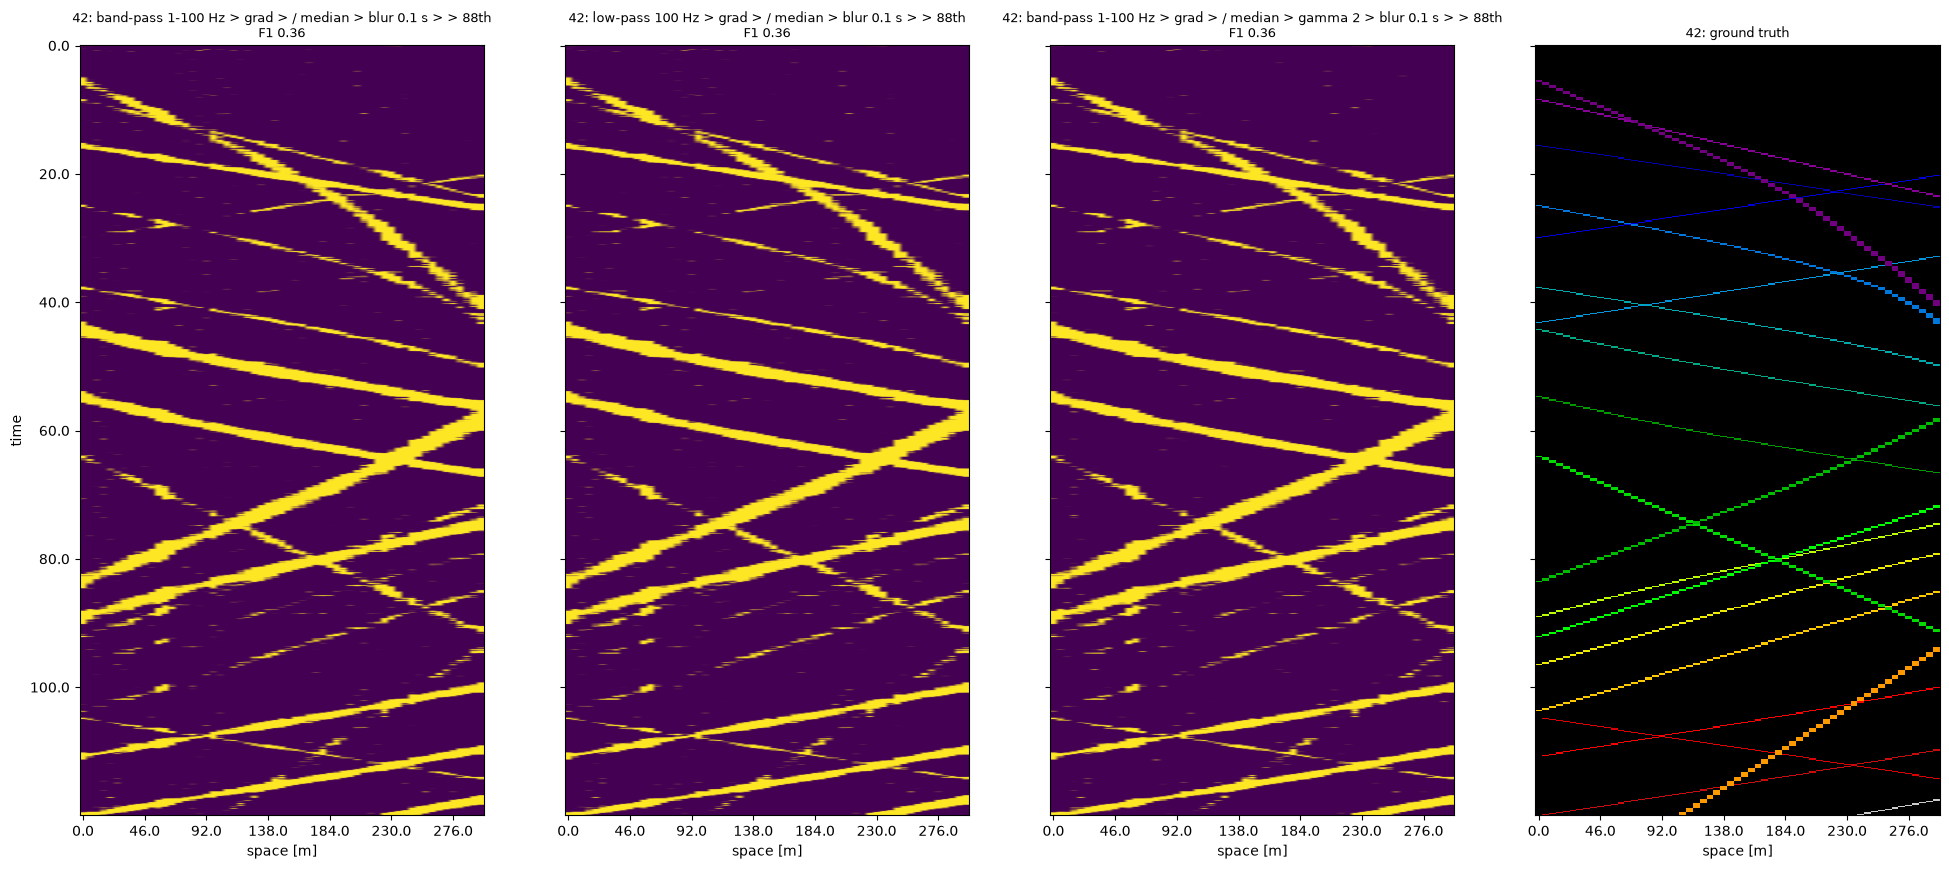

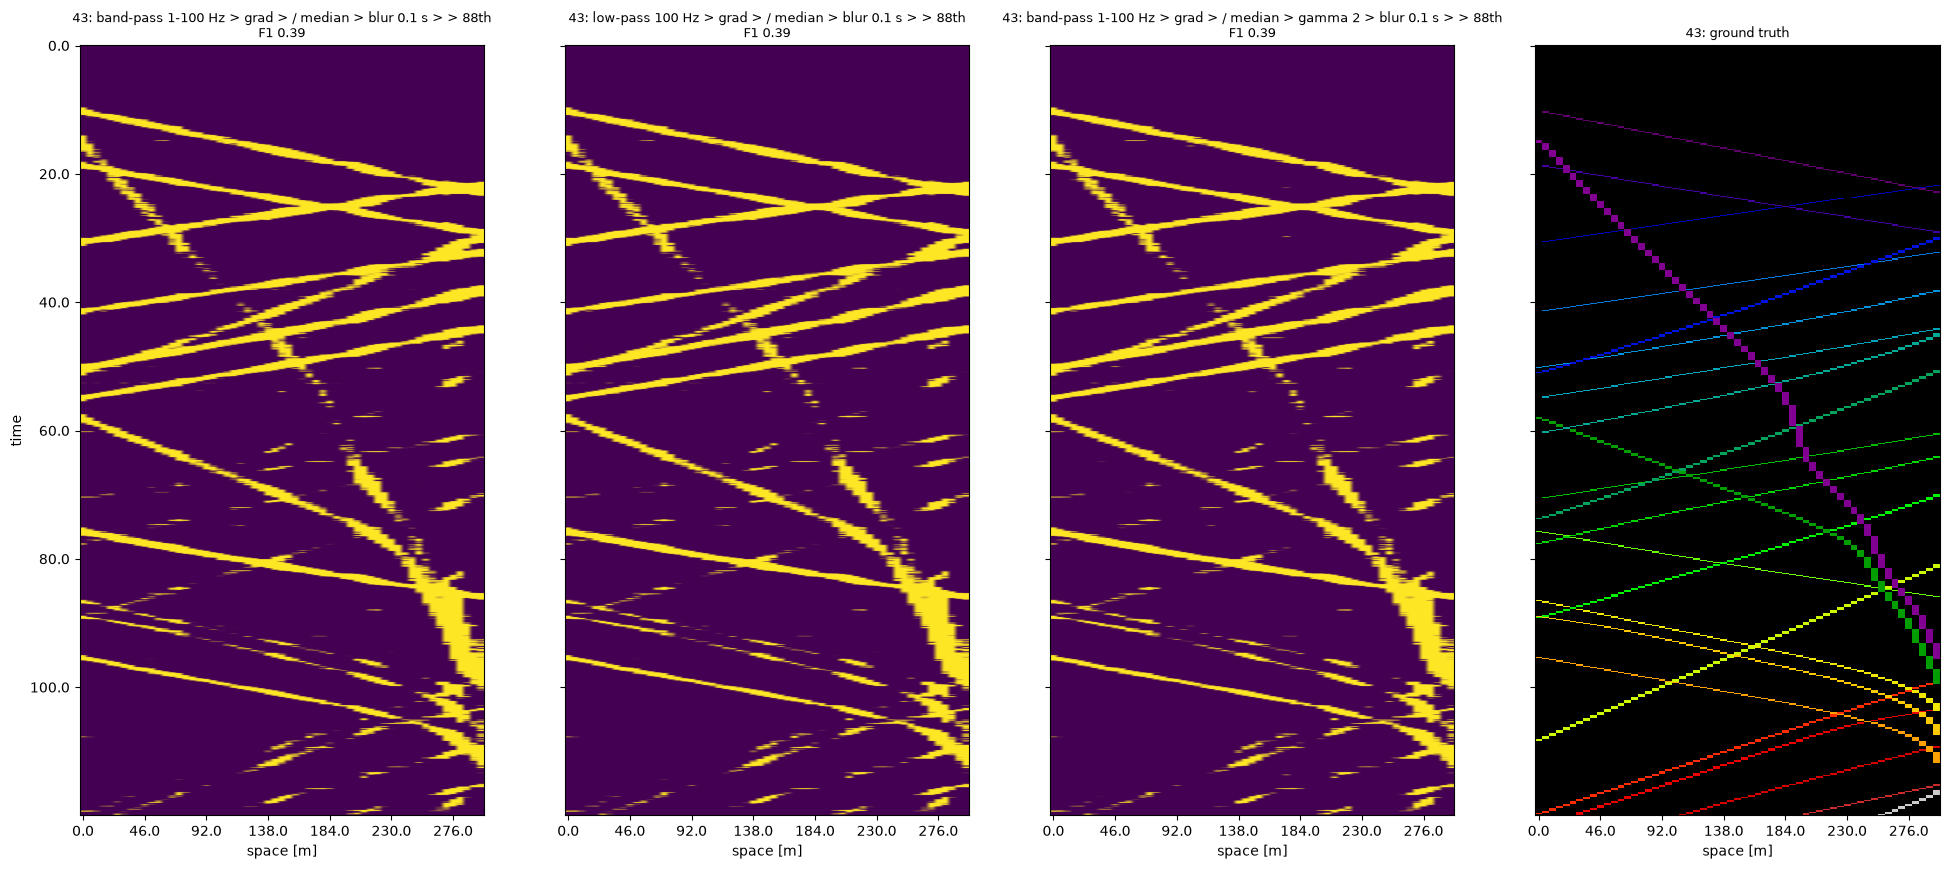

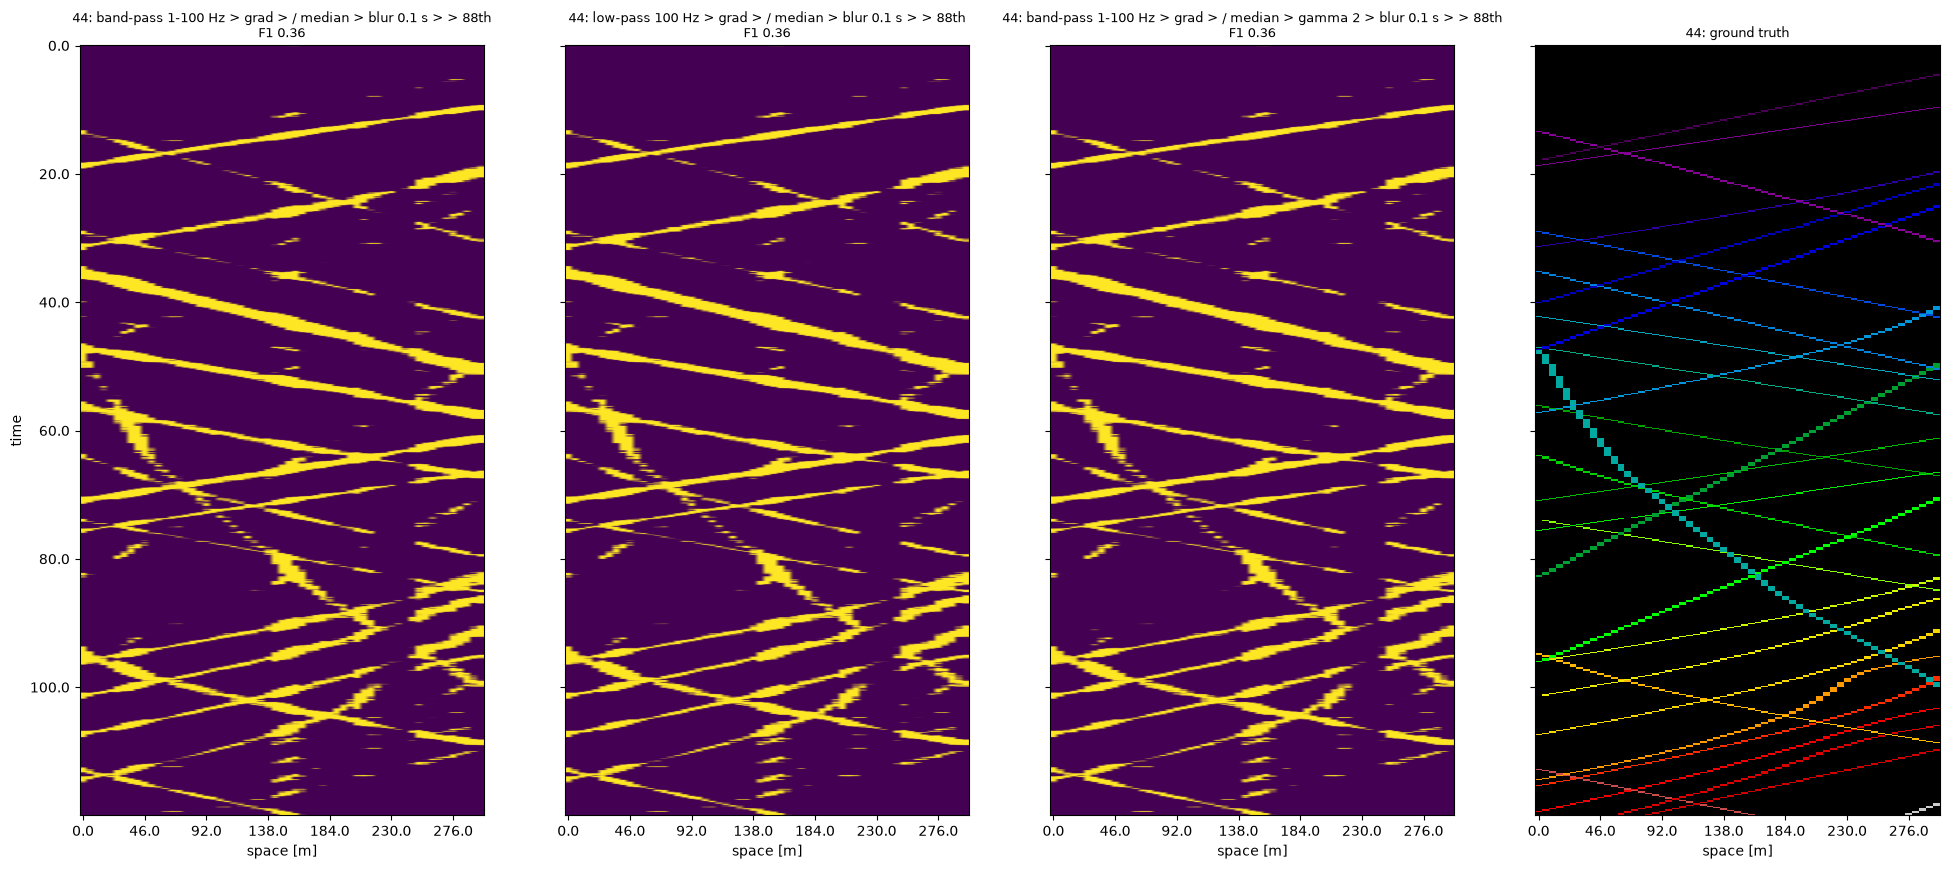

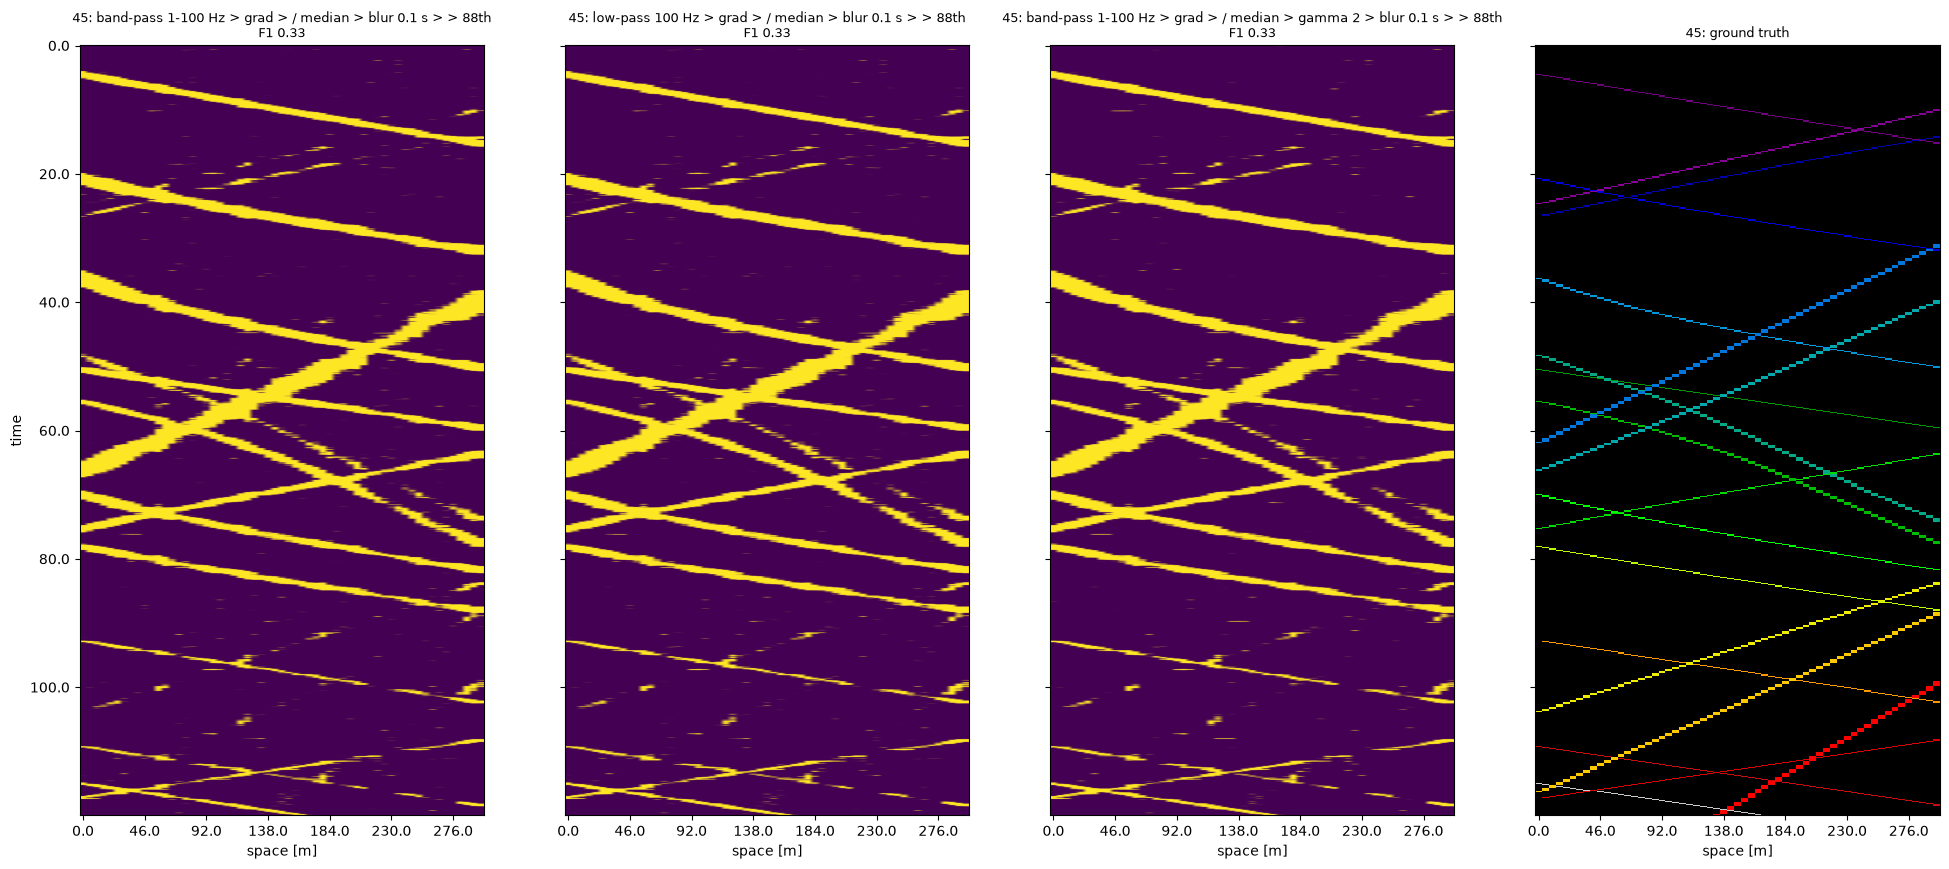

In [10]:
# 3 best chains that differ in more than percentile / opening
top = []
for chain in f1.index:
    if chain[:5] not in [c[:5] for c in top]:
        top.append(chain)
    if len(top) == 3:
        break

for name, df in [('real', df_real), ('real2', df_real2)] + [(i, s['signal']) for i, s in synthetic.items()]:
    real = name in ('real', 'real2')
    n = len(top) + (0 if real else 1)
    fig, axes = plt.subplots(1, n, figsize=(6 * n, 10), sharey=True)
    for ax, chain in zip(axes, top):
        ax.imshow(run_chain(df.values, *chain), interpolation='antialiased', aspect='auto')
        ax.set_title(f'{name}: {chain_label(chain)}' + ('' if real else f'\nF1 {f1.loc[chain, name]:.2f}'), fontsize=9)
    if not real:
        axes[-1].imshow(synthetic[name]['ground_truth'], interpolation='none', aspect='auto', cmap='nipy_spectral')
        axes[-1].set_title(f'{name}: ground truth', fontsize=9)

    x_positions, x_labels = set_axis(df.columns)
    for ax in axes:
        ax.set_xticks(x_positions, np.round(x_labels))
        ax.set_xlabel('space [m]')
    y_positions, y_labels = set_axis(df.index.time if real else np.round(df.index, 1))
    axes[0].set_yticks(y_positions, y_labels)
    axes[0].set_ylabel('time')
    plt.show()